In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

url = "https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/master/csv/datasets/faithful.csv"

df = pd.read_csv(url, index_col=0)
df.columns = ['eruption_duration', 'waiting_time']

print(df.head())
print("Dataset shape:", df.shape)
print(df.columns.tolist())

          eruption_duration  waiting_time
rownames                                 
1                     3.600            79
2                     1.800            54
3                     3.333            74
4                     2.283            62
5                     4.533            85
Dataset shape: (272, 2)
['eruption_duration', 'waiting_time']


In [9]:
X = df[['waiting_time', 'eruption_duration']]
print(X.describe())

       waiting_time  eruption_duration
count    272.000000         272.000000
mean      70.897059           3.487783
std       13.594974           1.141371
min       43.000000           1.600000
25%       58.000000           2.162750
50%       76.000000           4.000000
75%       82.000000           4.454250
max       96.000000           5.100000


In [10]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

print(df.head())

          eruption_duration  waiting_time  Cluster
rownames                                          
1                     3.600            79        0
2                     1.800            54        1
3                     3.333            74        0
4                     2.283            62        1
5                     4.533            85        0


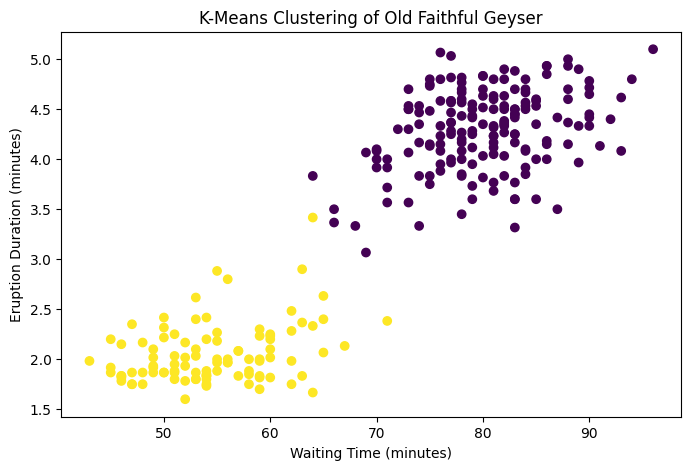

In [11]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df['waiting_time'],
    df['eruption_duration'],
    c=df['Cluster'],
    cmap='viridis'
)

plt.xlabel("Waiting Time (minutes)")
plt.ylabel("Eruption Duration (minutes)")
plt.title("K-Means Clustering of Old Faithful Geyser")
plt.show()

In [12]:
print(df.groupby('Cluster')[
    ['waiting_time', 'eruption_duration']
].mean().round(2))

         waiting_time  eruption_duration
Cluster                                 
0               80.08               4.30
1               54.59               2.05
